# GHNet

1. 环境与依赖检查
2. 参数与路径配置(**在第 2 节自行修改**)
3. 加载 `GHNet` (Encoder + Decoder + GHEM + RCMM)
4. 加载并展示 Content / Style 图
5. 单对推理 + 推理耗时
6. 结果对比可视化
7. 指标评估 (DISTS / Color Histogram Loss)
   - 7.5 多域 DISTS (Grayscale / LDC edge / HED edge)

## 1. 环境与依赖检查

In [1]:
import os, sys, time
import torch
from PIL import Image
from torchvision import transforms
from torchvision.utils import save_image
import matplotlib.pyplot as plt
from tqdm.notebook import tqdm

print('Python      :', sys.version.split()[0])
print('PyTorch     :', torch.__version__)
print('CUDA 可用   :', torch.cuda.is_available())
if torch.cuda.is_available():
    print('GPU         :', torch.cuda.get_device_name(0))

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('使用设备    :', device)

Python      : 3.11.4
PyTorch     : 2.1.0+cu121
CUDA 可用   : True
GPU         : NVIDIA GeForce RTX 4050 Laptop GPU
使用设备    : cuda


## 2. 参数与路径配置

> **答辩演示时,可在这里直接修改 `CONTENT_PATH` 与 `STYLE_PATH` 切换演示图片。**

In [2]:
# === 演示用 content / style 图 (在这里改) ===
CONTENT_PATH = r"E:\备份\gh\ghnet\content\0000556.png"
STYLE_PATH   = r"E:\备份\gh\ghnet\style\0000556.png"

# === 模型权重 (与 test.py 默认值一致) ===
ENCODER_PATH = r"E:\备份\gh\ghnet\ckpts\vgg_encoder.pth"
DECODER_PATH = r"E:\备份\gh\ghnet\saved_decoder_and_skip_models_2026_01_23_H_L\decoder_full.pth"
SKIP_PATH    = r"E:\备份\gh\ghnet\saved_decoder_and_skip_models_2026_01_23_H_L\skip_full.pth"
COLOR_PATH   = r"E:\备份\gh\ghnet\saved_progressive_color_models111\color_blocks_progressive.pth"

# === 推理 / 批量参数 ===
IMAGE_SIZE   = 512
OUTPUT_DIR   = r"E:\备份\gh\ghnet\results_demo"

os.makedirs(OUTPUT_DIR, exist_ok=True)

# 路径自检,避免现场翻车
for tag, p in [('CONTENT', CONTENT_PATH), ('STYLE', STYLE_PATH),
               ('ENCODER', ENCODER_PATH), ('DECODER', DECODER_PATH),
               ('SKIP', SKIP_PATH), ('COLOR', COLOR_PATH)]:
    flag = '存在' if os.path.exists(p) else '缺失'
    print(f'[{flag}] {tag:8s} -> {p}')

[存在] CONTENT  -> E:\备份\gh\ghnet\content\0000556.png
[存在] STYLE    -> E:\备份\gh\ghnet\style\0000556.png
[存在] ENCODER  -> E:\备份\gh\ghnet\ckpts\vgg_encoder.pth
[存在] DECODER  -> E:\备份\gh\ghnet\saved_decoder_and_skip_models_2026_01_23_H_L\decoder_full.pth
[存在] SKIP     -> E:\备份\gh\ghnet\saved_decoder_and_skip_models_2026_01_23_H_L\skip_full.pth
[存在] COLOR    -> E:\备份\gh\ghnet\saved_progressive_color_models111\color_blocks_progressive.pth


## 3. 加载 `GHNet`

`GHNet` 由四部分组成:

- **VGG Encoder**:多尺度特征提取
- **Decoder**:特征到图像的重建
- **GHEM (梯度引导高频增强模块)**:基于平均梯度引导的高频信息增强,在跳连路径上保留并强化结构与纹理细节
- **RCMM (基于排序的颜色调制模块)**:通过对特征通道排序进行颜色统计对齐,从粗到细完成颜色迁移

In [3]:
# === GHNet 模型定义 (内联自 models_pro.py) ===
import sys
sys.path.insert(0, r"E:\备份\gh\ghnet")  # 让 utils.model_conv_torch 可被导入

import torch
import torch.nn as nn
import torch.nn.functional as F
from einops import rearrange

from utils.model_conv_torch import VggEncoder, VggDecoder


# ---------- 特征级风格迁移辅助 (ZCA / OT / AdaIN, 当前 forward 已不使用) ----------
def inv_sqrt_cov(cov, inverse=False):
    """对协方差矩阵做 SVD, 返回 C^{1/2} 或 C^{-1/2}。"""
    u, s, vh = torch.linalg.svd(cov)
    n_s = (s > 1e-5).sum()
    s = s[:n_s]
    u = u[:, :n_s]
    s_sqrt = torch.sqrt(s)
    if inverse:
        s_sqrt = 1.0 / s_sqrt
    d = torch.diag(s_sqrt)
    return torch.mm(torch.mm(u, d), u.t())


def stylize_adain(c_feat, s_feat):
    c_mean = torch.mean(c_feat, dim=1, keepdim=True)
    s_mean = torch.mean(s_feat, dim=1, keepdim=True)
    c_std = torch.std(c_feat, dim=1, keepdim=True) + 1e-8
    s_std = torch.std(s_feat, dim=1, keepdim=True) + 1e-8
    return s_std * (c_feat - c_mean) / c_std + s_mean


def stylize_zca(c_feat, s_feat):
    c_mean = torch.mean(c_feat, dim=1, keepdim=True)
    s_mean = torch.mean(s_feat, dim=1, keepdim=True)
    c_centered = c_feat - c_mean
    s_centered = s_feat - s_mean
    c_cov = torch.mm(c_centered, c_centered.t()) / (c_feat.shape[1] - 1)
    s_cov = torch.mm(s_centered, s_centered.t()) / (s_feat.shape[1] - 1)
    c_inv_sqrt = inv_sqrt_cov(c_cov, inverse=True)
    s_sqrt = inv_sqrt_cov(s_cov, inverse=False)
    transform_matrix = torch.mm(s_sqrt, c_inv_sqrt)
    return torch.mm(transform_matrix, c_centered) + s_mean


def stylize_ot(c_feat, s_feat):
    c_mean = torch.mean(c_feat, dim=1, keepdim=True)
    s_mean = torch.mean(s_feat, dim=1, keepdim=True)
    c_centered = c_feat - c_mean
    s_centered = s_feat - s_mean
    c_cov = torch.mm(c_centered, c_centered.t()) / (c_feat.shape[1] - 1)
    s_cov = torch.mm(s_centered, s_centered.t()) / (s_feat.shape[1] - 1)
    sqrt_c = inv_sqrt_cov(c_cov, inverse=False)
    inv_sqrt_c = inv_sqrt_cov(c_cov, inverse=True)
    middle = torch.mm(torch.mm(sqrt_c, s_cov), sqrt_c)
    sqrt_middle = inv_sqrt_cov(middle, inverse=False)
    transform_matrix = torch.mm(torch.mm(inv_sqrt_c, sqrt_middle), inv_sqrt_c)
    return torch.mm(transform_matrix, c_centered) + s_mean


def stylize_core(c_feat, s_feat, opt='zca'):
    B, C, H, W = c_feat.size()
    c_flat = c_feat.view(B, C, -1).double()
    s_flat = s_feat.view(B, C, -1).double()
    out_list = []
    for i in range(B):
        cF = c_flat[i]
        sF = s_flat[i]
        if opt == 'zca':
            res = stylize_zca(cF, sF)
        elif opt == 'ot':
            res = stylize_ot(cF, sF)
        elif opt == 'adain':
            res = stylize_adain(cF, sF)
        else:
            res = cF
        out_list.append(res.float().view(1, C, H, W))
    return torch.cat(out_list, dim=0)


def calc_mean_std(feat, eps=1e-5):
    size = feat.size()
    N, C = size[:2]
    feat_var = feat.view(N, C, -1).var(dim=2) + eps
    feat_std = feat_var.sqrt().view(N, C, 1, 1)
    feat_mean = feat.view(N, C, -1).mean(dim=2).view(N, C, 1, 1)
    return feat_mean, feat_std


def compute_gradient(image):
    if image.dim() == 3:
        image = image.unsqueeze(0)
    sobel_x = torch.tensor([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]],
                           dtype=torch.float32, device=image.device).view(1, 1, 3, 3)
    sobel_y = torch.tensor([[-1, -2, -1], [0, 0, 0], [1, 2, 1]],
                           dtype=torch.float32, device=image.device).view(1, 1, 3, 3)
    sobel_x = sobel_x.repeat(image.shape[1], 1, 1, 1)
    sobel_y = sobel_y.repeat(image.shape[1], 1, 1, 1)
    grad_x = F.conv2d(image, sobel_x, padding=1, groups=image.shape[1])
    grad_y = F.conv2d(image, sobel_y, padding=1, groups=image.shape[1])
    return torch.sqrt(grad_x ** 2 + grad_y ** 2 + 1e-8)


# ---------- 模块定义 ----------
class GammaNet(nn.Module):
    def __init__(self, input_channels=3, feature_channels=16):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(input_channels, feature_channels, kernel_size=3, padding=1),
            nn.BatchNorm2d(feature_channels),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(feature_channels, feature_channels * 2, kernel_size=3, padding=1),
            nn.BatchNorm2d(feature_channels * 2),
            nn.LeakyReLU(0.2, inplace=True),
        )
        self.gamma_pred = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),
            nn.Flatten(),
            nn.Linear(feature_channels * 2, 1),
        )

    def forward(self, x):
        return self.gamma_pred(self.features(x)).view(-1, 1, 1, 1)


class Depth_conv(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.depth_conv = nn.Conv2d(in_ch, in_ch, 3, 1, 1, groups=in_ch)
        self.point_conv = nn.Conv2d(in_ch, out_ch, 1, 1, 0)

    def forward(self, x):
        return self.point_conv(self.depth_conv(x))


class GHEM(nn.Module):
    """梯度引导高频增强模块 (Gradient-guided High-frequency Enhancement Module)。"""

    def __init__(self, in_nf, out_if, nf):
        super().__init__()
        self.avg_pool = nn.AvgPool2d(kernel_size=3, stride=1, padding=1)
        self.gamma_net = GammaNet(in_nf, nf // 4)
        self.conv1 = nn.Sequential(nn.Conv2d(in_nf, nf, 3, 1, 1), nn.LeakyReLU(0.1))
        self.conv2 = nn.Sequential(nn.Conv2d(in_nf, nf, 3, 1, 1), nn.LeakyReLU(0.1))
        self.conv3 = nn.Sequential(
            nn.Conv2d(nf, nf, 3, 1, 1), nn.LeakyReLU(0.1),
            nn.Conv2d(nf, 1, 1, 1, 0), nn.Sigmoid(),
        )
        self.conv_process = nn.Sequential(
            Depth_conv(in_ch=in_nf, out_ch=nf), nn.LeakyReLU(0.1),
            nn.Conv2d(nf, out_if, 1, 1, 0),
        )

    def forward(self, dec_feat, enc_skip):
        if dec_feat.size()[2:] != enc_skip.size()[2:]:
            dec_feat = F.interpolate(dec_feat, size=enc_skip.shape[2:],
                                     mode='bilinear', align_corners=False)
        x_LL = self.avg_pool(enc_skip)
        x_H = enc_skip
        gamma = self.gamma_net(x_LL)
        gamma = torch.sigmoid(gamma) * 2 + 0.5
        x_LL_gamma = torch.sign(x_LL) * torch.pow(torch.clamp(torch.abs(x_LL), min=1e-6), gamma)
        fg = compute_gradient(x_LL_gamma)
        att = self.conv1(fg) * self.conv2(x_H)
        mask = self.conv3(att)
        out = self.conv_process(x_H * mask + x_H)
        return out


class RCMM(nn.Module):
    """基于排序的颜色调制模块 (Sort-based Color Modulation Module)。"""

    def __init__(self, dim, num_heads=4, use_sort=True):
        super().__init__()
        self.num_heads = num_heads
        self.head_dim = dim // num_heads
        if dim % num_heads != 0:
            num_heads = 1
        self.temperature = nn.Parameter(torch.ones(num_heads, 1, 1))
        self.to_kv = nn.Sequential(
            nn.Conv2d(dim, dim * 2, kernel_size=1),
            nn.Conv2d(dim * 2, dim * 2, kernel_size=3, padding=1, groups=dim * 2),
        )
        self.to_q = nn.Sequential(
            nn.Conv2d(dim, dim, kernel_size=1),
            nn.Conv2d(dim, dim, kernel_size=3, padding=1, groups=dim),
        )
        self.proj = nn.Conv2d(dim, dim, kernel_size=1)
        self.use_sort = use_sort

    def forward(self, x_content, x_color):
        B, C, H, W = x_content.shape
        if x_color.shape[2:] != x_content.shape[2:]:
            x_color = F.interpolate(x_color, size=(H, W), mode='bilinear', align_corners=False)
        q = self.to_q(x_content)
        kv = self.to_kv(x_color)
        k, v = kv.chunk(2, dim=1)
        if self.use_sort:
            q, idx_q = q.view(B, C, -1).sort(dim=-1)
            v, idx_v = v.view(B, C, -1).sort(dim=-1)
            k = torch.gather(k.view(B, C, -1), dim=-1, index=idx_v)
        q = rearrange(q, 'b (head c) a -> b head c a', head=self.num_heads)
        k = rearrange(k, 'b (head c) a -> b head c a', head=self.num_heads)
        v = rearrange(v, 'b (head c) a -> b head c a', head=self.num_heads)
        q = F.normalize(q, dim=-1)
        k = F.normalize(k, dim=-1)
        attn = torch.matmul(q, k.transpose(-2, -1)) * self.temperature
        attn = attn.softmax(dim=-1)
        out = torch.matmul(attn, v)
        out = rearrange(out, 'b head c (h w) -> b (head c) (h w)', h=H, w=W)
        restored = torch.zeros_like(out)
        restored.scatter_(-1, idx_q, out)
        out = restored
        out = rearrange(out, 'b C (h w) -> b C  h  w', h=H, w=W)
        out = self.proj(out)
        return out + x_content


class GHNet(nn.Module):
    def __init__(self, device='cuda'):
        super().__init__()
        self.device = device
        self.encoder = VggEncoder()
        self.decoder = VggDecoder()
        self.skip_blocks = nn.ModuleDict({
            '1': GHEM(64, 64, 64),
            '2': GHEM(128, 128, 128),
            '3': GHEM(256, 256, 256),
        })
        self.color_blocks = nn.ModuleDict({
            '3': RCMM(512, 4),  # Bottleneck
            '2': RCMM(256, 4),
            '1': RCMM(128, 4),
            '0': RCMM(64, 4),
        })

    def load_weights(self, enc_path, dec_path, skip_path, color_path):
        print(f"Loading Encoder: {enc_path}")
        self.encoder.load_state_dict(torch.load(enc_path, map_location=self.device))
        print(f"Loading Decoder: {dec_path}")
        self.decoder.load_state_dict(torch.load(dec_path, map_location=self.device))
        print(f"Loading Skip Blocks: {skip_path}")
        self.skip_blocks.load_state_dict(torch.load(skip_path, map_location=self.device))
        print(f"Loading Color Blocks: {color_path}")
        self.color_blocks.load_state_dict(torch.load(color_path, map_location=self.device))
        self.to(self.device)
        self.eval()

    def forward(self, content_img, style_img):
        con_feats = []
        skip_feats = [None]
        style_feats = []

        # Content 多尺度特征
        out = self.encoder(0, content_img)
        x_c = out[0]
        con_feats.append(x_c)
        for l in range(1, 4):
            out = self.encoder(l, x_c)
            x_c = out[0]
            skip_c = out[1]
            con_feats.append(x_c)
            skip_feats.append(skip_c)

        # Style 多尺度特征
        out = self.encoder(0, style_img)
        x_s = out[0]
        style_feats.append(x_s)
        for l in range(1, 4):
            out = self.encoder(l, x_s)
            x_s = out[0]
            style_feats.append(x_s)

        # 解码 + GHEM + RCMM 全尺度上色
        curr_dec = con_feats[-1]
        for l in reversed(range(4)):
            if l > 0:
                skip_guided = self.skip_blocks[str(l)](curr_dec, skip_feats[l])
                curr_feat = self.color_blocks[str(l)](curr_dec, style_feats[l])
                curr_dec = self.decoder(l, curr_feat, skip=skip_guided)
            else:
                curr_feat = self.color_blocks[str(l)](curr_dec, style_feats[l])
                curr_dec = self.decoder(0, curr_feat, skip=None)
        return curr_dec

In [4]:
net = GHNet(device=device)
net.load_weights(ENCODER_PATH, DECODER_PATH, SKIP_PATH, COLOR_PATH)

total_params = sum(p.numel() for p in net.parameters())
print(f'模型参数量: {total_params/1e6:.2f} M')

Reached target layer: conv4_1
Loading Encoder: E:\备份\gh\ghnet\ckpts\vgg_encoder.pth
Loading Decoder: E:\备份\gh\ghnet\saved_decoder_and_skip_models_2026_01_23_H_L\decoder_full.pth
Loading Skip Blocks: E:\备份\gh\ghnet\saved_decoder_and_skip_models_2026_01_23_H_L\skip_full.pth
Loading Color Blocks: E:\备份\gh\ghnet\saved_progressive_color_models111\color_blocks_progressive.pth
模型参数量: 11.23 M


## 4. 图像加载与预览

Content tensor: (1, 3, 512, 512)
Style   tensor: (1, 3, 512, 512)


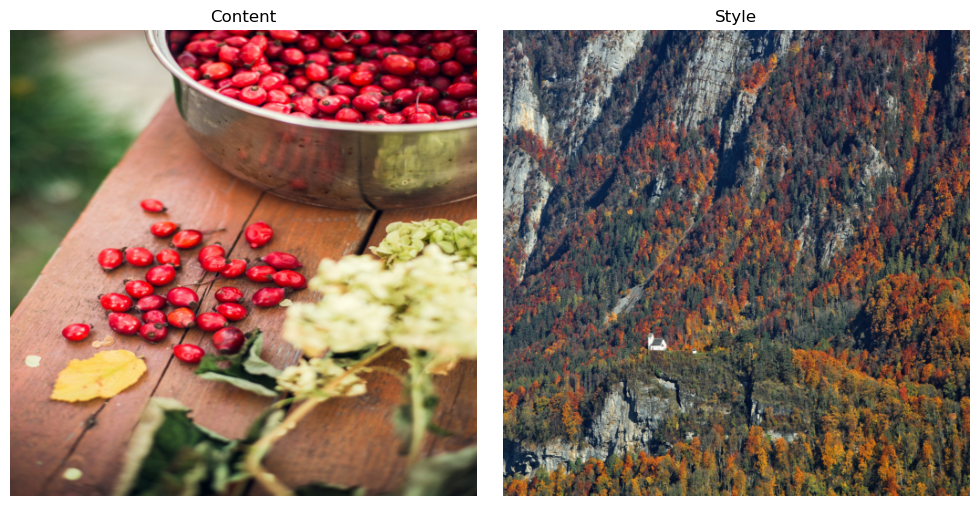

In [5]:
def load_image(path, size=IMAGE_SIZE, device=device):
    if not os.path.exists(path):
        raise FileNotFoundError(f'Image not found: {path}')
    transform = transforms.Compose([
        transforms.Resize((size, size)),
        transforms.ToTensor(),
    ])
    img = Image.open(path).convert('RGB')
    return transform(img).unsqueeze(0).to(device)


def tensor_to_np(t):
    """(1,C,H,W) -> (H,W,C) numpy, clip 到 [0,1]"""
    return t.detach().squeeze(0).clamp(0, 1).permute(1, 2, 0).cpu().numpy()


content_img = load_image(CONTENT_PATH)
style_img   = load_image(STYLE_PATH)
print('Content tensor:', tuple(content_img.shape))
print('Style   tensor:', tuple(style_img.shape))

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].imshow(tensor_to_np(content_img)); axes[0].set_title('Content'); axes[0].axis('off')
axes[1].imshow(tensor_to_np(style_img));   axes[1].set_title('Style');   axes[1].axis('off')
plt.tight_layout(); plt.show()

## 5. 单对推理 + 耗时统计

In [6]:
with torch.no_grad():
    if device.type == 'cuda':
        torch.cuda.synchronize()
    t0 = time.time()
    output = net(content_img, style_img)
    if device.type == 'cuda':
        torch.cuda.synchronize()
    dt = time.time() - t0
    output = torch.clamp(output, 0, 1)

print(f'输入尺寸: {IMAGE_SIZE}x{IMAGE_SIZE}  推理耗时: {dt*1000:.1f} ms')

save_name = os.path.splitext(os.path.basename(CONTENT_PATH))[0] + '_stylized.png'
save_path = os.path.join(OUTPUT_DIR, save_name)
save_image(output, save_path)
print('结果已保存:', save_path)

输入尺寸: 512x512  推理耗时: 1694.3 ms
结果已保存: E:\备份\gh\ghnet\results_demo\0000556_stylized.png


## 6. Content / Style / Output 三栏对比

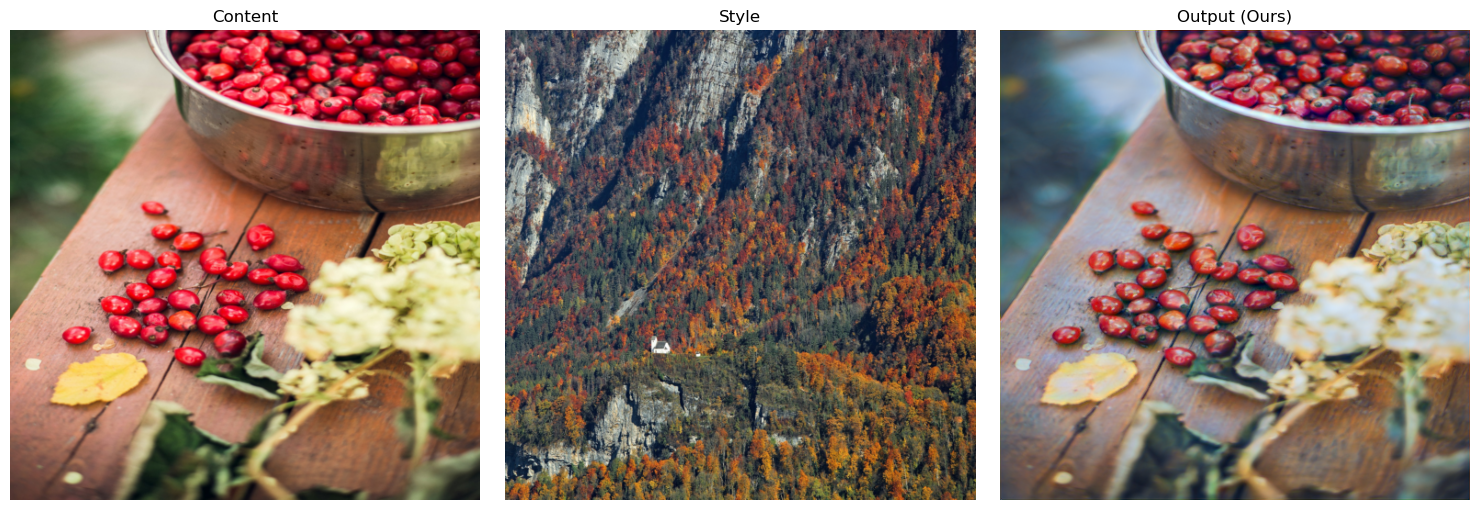

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(tensor_to_np(content_img)); axes[0].set_title('Content'); axes[0].axis('off')
axes[1].imshow(tensor_to_np(style_img));   axes[1].set_title('Style');   axes[1].axis('off')
axes[2].imshow(tensor_to_np(output));      axes[2].set_title('Output (Ours)'); axes[2].axis('off')
plt.tight_layout(); plt.show()

## 7. 指标评估

- **DISTS**:衡量输出与 content 的结构/纹理一致性,越低越好
- **HistLoss**:衡量输出与 style 的颜色直方图距离,越低越好

In [8]:
from metrics import MetricCalculator

evaluator = MetricCalculator(device=device)
scores = evaluator.compute(content_img, style_img, output)

print('=' * 30)
for k, v in scores.items():
    print(f'{k:10s}: {v:.4f}')
print('=' * 30)

D:\anaconda3\Lib\site-packages\torchvision\models\_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
D:\anaconda3\Lib\site-packages\torchvision\models\_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=VGG16_Weights.IMAGENET1K_V1`. You can also use `weights=VGG16_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


DISTS     : 0.1074
HistLoss  : 0.2808


## 7.5 多域 DISTS 评估 (Grayscale / LDC edge / HED edge)

**独立单元格** —— 直接从磁盘读 `content` 和**之前已生成的** stylized 输出,不依赖前面任何 cell。
把两张图分别投影到 灰度 / LDC 边缘 / HED 边缘 三个域,各自计算 DISTS,衡量结构 / 边缘 / 亮度是否被风格迁移破坏。

- **LDC**: `D:\code\sample\LDC-main` (modelB4 + BIPED checkpoint)
- **HED**: `D:\code\sample\pytorch-hed-master\network-bsds500.pytorch`

content: (1, 3, 512, 512) (E:\备份\gh\ghnet\content\0000556.png)
output : (1, 3, 512, 512) (E:\备份\gh\ghnet\content\0000556.png)
LDC loaded.
HED loaded.
DISTS (content ↔ output) 多域评估
--------------------------------------------
  Raw  RGB        : -0.0000
  Grayscale       : -0.0000
  LDC  edge (B4)  : 0.0000
  HED  edge       : -0.0000


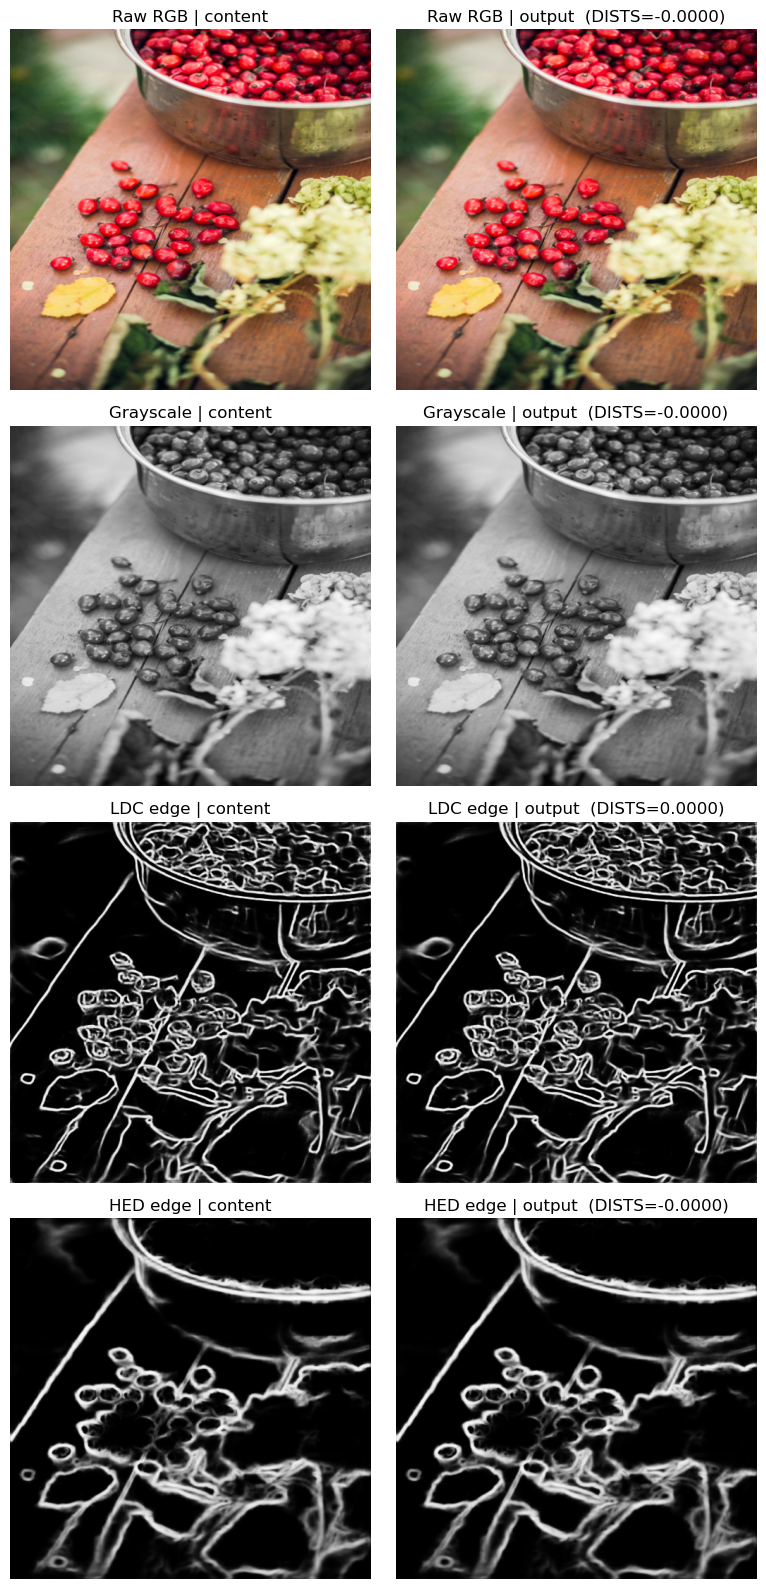

In [10]:
# ========== 多域 DISTS:Grayscale / LDC / HED (独立 cell) ==========
# 直接读盘:content + 之前已生成的 stylized,无需 GHNet 推理

import sys
sys.path.insert(0, r"D:\code\sample\LDC-main")  # 让 modelB4 可 import

import torch
import torch.nn as nn
import torch.nn.functional as F
from PIL import Image
from torchvision import transforms
import matplotlib.pyplot as plt

from DISTS_pytorch import DISTS as _DISTS
from modelB4 import LDC as _LDCModel

# ---- 0. 配置:在这里修改要对比的两张图 ----
CONTENT_FOR_EVAL = CONTENT_PATH
OUTPUT_FOR_EVAL  = r"E:\备份\gh\ghnet\content\0000556.png"
IMG_SIZE = 512

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


def _load_img(path, size=IMG_SIZE):
    tr = transforms.Compose([transforms.Resize((size, size)), transforms.ToTensor()])
    return tr(Image.open(path).convert("RGB")).unsqueeze(0).to(device)


def _to_np(t):
    return t.detach().squeeze(0).clamp(0, 1).permute(1, 2, 0).cpu().numpy()


content_eval = _load_img(CONTENT_FOR_EVAL)
output_eval  = _load_img(OUTPUT_FOR_EVAL)
print(f"content: {tuple(content_eval.shape)} ({CONTENT_FOR_EVAL})")
print(f"output : {tuple(output_eval.shape)} ({OUTPUT_FOR_EVAL})")

# ---- 1. LDC (modelB4 + BIPED checkpoint) ----
LDC_CKPT = r"D:\code\sample\LDC-main\checkpoints\BIPED\16\16_model.pth"
LDC_MEAN_BGR = torch.tensor([103.939, 116.779, 123.68], device=device).view(1, 3, 1, 1)

ldc_model = _LDCModel().to(device)
ldc_model.load_state_dict(torch.load(LDC_CKPT, map_location=device))
ldc_model.eval()
for _p in ldc_model.parameters():
    _p.requires_grad = False
print("LDC loaded.")

# ---- 2. HED (内联 Network, 跳过 run.py 中的联网下载, 加载本地权重) ----
HED_CKPT = r"D:\code\sample\pytorch-hed-master\network-bsds500.pytorch"
HED_MEAN_BGR = torch.tensor([104.00698793, 116.66876762, 122.67891434],
                            device=device).view(1, 3, 1, 1)


class _HEDNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.netVggOne = nn.Sequential(
            nn.Conv2d(3, 64, 3, 1, 1), nn.ReLU(inplace=False),
            nn.Conv2d(64, 64, 3, 1, 1), nn.ReLU(inplace=False),
        )
        self.netVggTwo = nn.Sequential(
            nn.MaxPool2d(2, 2),
            nn.Conv2d(64, 128, 3, 1, 1), nn.ReLU(inplace=False),
            nn.Conv2d(128, 128, 3, 1, 1), nn.ReLU(inplace=False),
        )
        self.netVggThr = nn.Sequential(
            nn.MaxPool2d(2, 2),
            nn.Conv2d(128, 256, 3, 1, 1), nn.ReLU(inplace=False),
            nn.Conv2d(256, 256, 3, 1, 1), nn.ReLU(inplace=False),
            nn.Conv2d(256, 256, 3, 1, 1), nn.ReLU(inplace=False),
        )
        self.netVggFou = nn.Sequential(
            nn.MaxPool2d(2, 2),
            nn.Conv2d(256, 512, 3, 1, 1), nn.ReLU(inplace=False),
            nn.Conv2d(512, 512, 3, 1, 1), nn.ReLU(inplace=False),
            nn.Conv2d(512, 512, 3, 1, 1), nn.ReLU(inplace=False),
        )
        self.netVggFiv = nn.Sequential(
            nn.MaxPool2d(2, 2),
            nn.Conv2d(512, 512, 3, 1, 1), nn.ReLU(inplace=False),
            nn.Conv2d(512, 512, 3, 1, 1), nn.ReLU(inplace=False),
            nn.Conv2d(512, 512, 3, 1, 1), nn.ReLU(inplace=False),
        )
        self.netScoreOne = nn.Conv2d(64, 1, 1)
        self.netScoreTwo = nn.Conv2d(128, 1, 1)
        self.netScoreThr = nn.Conv2d(256, 1, 1)
        self.netScoreFou = nn.Conv2d(512, 1, 1)
        self.netScoreFiv = nn.Conv2d(512, 1, 1)
        self.netCombine = nn.Sequential(nn.Conv2d(5, 1, 1), nn.Sigmoid())

    def forward(self, x_rgb01):
        x = x_rgb01[:, [2, 1, 0], :, :] * 255.0 - HED_MEAN_BGR
        v1 = self.netVggOne(x)
        v2 = self.netVggTwo(v1)
        v3 = self.netVggThr(v2)
        v4 = self.netVggFou(v3)
        v5 = self.netVggFiv(v4)
        H, W = x.shape[2], x.shape[3]

        def up(s, f):
            return F.interpolate(s(f), size=(H, W), mode='bilinear', align_corners=False)

        cat = torch.cat([up(self.netScoreOne, v1),
                         up(self.netScoreTwo, v2),
                         up(self.netScoreThr, v3),
                         up(self.netScoreFou, v4),
                         up(self.netScoreFiv, v5)], dim=1)
        return self.netCombine(cat)


hed_model = _HEDNet().to(device)
_hed_sd = torch.load(HED_CKPT, map_location=device)
hed_model.load_state_dict({k.replace('module', 'net'): v for k, v in _hed_sd.items()})
hed_model.eval()
for _p in hed_model.parameters():
    _p.requires_grad = False
print("HED loaded.")

# ---- 3. 三种投影:gray / LDC / HED,全部输出 3 通道 ∈ [0,1] ----
_GRAY_W = torch.tensor([0.299, 0.587, 0.114], device=device).view(1, 3, 1, 1)


def to_gray3(x_rgb01):
    g = (x_rgb01 * _GRAY_W).sum(dim=1, keepdim=True)
    return g.repeat(1, 3, 1, 1).clamp(0, 1)


@torch.no_grad()
def to_ldc_edge3(x_rgb01):
    preds = ldc_model(x_rgb01 * 255.0 - LDC_MEAN_BGR)
    return torch.sigmoid(preds[-1]).repeat(1, 3, 1, 1).clamp(0, 1)


@torch.no_grad()
def to_hed_edge3(x_rgb01):
    return hed_model(x_rgb01).repeat(1, 3, 1, 1).clamp(0, 1)

# ---- 4. 计算四个域的 DISTS ----
_dists = _DISTS().to(device).eval()
for _p in _dists.parameters():
    _p.requires_grad = False


@torch.no_grad()
def dpair(a, b):
    return _dists(a, b).item()


with torch.no_grad():
    g_c, g_o = to_gray3(content_eval),     to_gray3(output_eval)
    l_c, l_o = to_ldc_edge3(content_eval), to_ldc_edge3(output_eval)
    h_c, h_o = to_hed_edge3(content_eval), to_hed_edge3(output_eval)
    d_raw  = dpair(content_eval, output_eval)
    d_gray = dpair(g_c, g_o)
    d_ldc  = dpair(l_c, l_o)
    d_hed  = dpair(h_c, h_o)

print('=' * 44)
print('DISTS (content ↔ output) 多域评估')
print('-' * 44)
print(f'  Raw  RGB        : {d_raw:.4f}')
print(f'  Grayscale       : {d_gray:.4f}')
print(f'  LDC  edge (B4)  : {d_ldc:.4f}')
print(f'  HED  edge       : {d_hed:.4f}')
print('=' * 44)

# ---- 5. 可视化 4 行 × 2 列 ----
rows = [
    ('Raw RGB',   content_eval, output_eval, d_raw),
    ('Grayscale', g_c, g_o, d_gray),
    ('LDC edge',  l_c, l_o, d_ldc),
    ('HED edge',  h_c, h_o, d_hed),
]
fig, axes = plt.subplots(4, 2, figsize=(8, 16))
for i, (name, c, o, d) in enumerate(rows):
    axes[i, 0].imshow(_to_np(c)); axes[i, 0].set_title(f'{name} | content'); axes[i, 0].axis('off')
    axes[i, 1].imshow(_to_np(o)); axes[i, 1].set_title(f'{name} | output  (DISTS={d:.4f})'); axes[i, 1].axis('off')
plt.tight_layout(); plt.show()